In [1]:
import numpy as np
import matplotlib.pyplot as plt
from nnfs.datasets import spiral_data
from sklearn.preprocessing import OneHotEncoder

### Individual Layers in NN

In [2]:
# 4 i/p, 2 hidden layers with 3 Neurons
x = np.random.rand(3, 4) # 3 batch of i/p
w0 = np.random.rand(3, 4) # assinging weights to each i/p
w1 = np.random.rand(3, 3) # assinging weights for 2nd layer i/p

B0 = np.random.rand(3, 1) # biases for first hidden layer
B1 = np.random.rand(3, 1) # biases for second hidden layer

In [3]:
# 1st hidden layer
l1 = x @ w0.T + B0
l1

array([[2.06880508, 1.57046922, 1.43418147],
       [2.26384377, 1.76013894, 1.41280903],
       [1.38150731, 1.15949839, 0.98114407]])

In [4]:
# 2nd hidden layer
l2 = l1 @ w1.T + B1
l2

array([[3.84675724, 1.22739918, 2.74024011],
       [4.27705375, 1.39391071, 3.05479196],
       [2.77966783, 0.95014908, 2.01780072]])

### Class of Dense Layer

In [5]:
class DenseLayer:
    
    def __init__(self, n_neurons, n_inputs): # number of neurons and number of inputs

        self.weights = np.random.randn(n_neurons, n_inputs)
        self.bias = np.zeros((1, n_neurons))
        
    def forward(self, x):
        return x @ self.weights.T + self.bias

In [6]:
dense_layer1 = DenseLayer(3, 4)
l1 = dense_layer1.forward(x)
l1 # output of first layer

array([[-0.48596686, -2.26315028, -0.48583326],
       [ 0.62256234, -3.5109682 , -1.05903804],
       [ 0.57632118, -2.99901154, -0.7547303 ]])

In [7]:
dense_layer2 = DenseLayer(3, 3)
dense_layer2.forward(l1) # output of second layer

array([[ 0.12048145,  2.68260653,  1.81085201],
       [-0.72456112,  5.8433475 ,  3.4661321 ],
       [-0.85770737,  4.7654219 ,  2.82869497]])

### Activation Function

In [8]:
class ActivationFunction:

    def ReLU(self, inputs):
        return np.maximum(0, inputs)

    def ReLU_der(self, inputs):
        return np.where(x>0, 1, 0)

    def Softmax(self, inputs):
        
        exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True))
        return exp_values / np.sum(exp_values, axis=1, keepdims=True)

In [9]:
a = [
    [2, -1, 4, 5],
    [3, 9, -4, -1],
    [5, -1, -2, 3]
]

inputs = np.random.randn(3, 4)
inputs

array([[-1.33138034, -0.35423578,  1.48675872, -0.80120889],
       [-0.2688974 ,  0.71868552, -1.19681142,  0.08376002],
       [-0.28258331,  0.17359017,  1.15324089,  1.12811818]])

In [10]:
af = ActivationFunction()
af.ReLU(a)

array([[2, 0, 4, 5],
       [3, 9, 0, 0],
       [5, 0, 0, 3]])

In [11]:
sm = af.Softmax(inputs)
sm

array([[0.0452453 , 0.12021039, 0.75766242, 0.07688189],
       [0.18172043, 0.48787163, 0.07184819, 0.25855975],
       [0.09191209, 0.14503949, 0.38631642, 0.376732  ]])

In [12]:
np.sum(sm, axis=1)

array([1., 1., 1.])

### Catergorical Cross Entropy Loss

In [13]:
actual_class = np.array([
    [0, 1, 0],
    [1, 0, 0],
    [0, 1, 0]
])

predicted_prob = np.array([
    [0.2, 0.7, 0.1],
    [0.3, 0.4, 0.3],
    [0.08, 0.9, 0.02]
])

# element wise multiplication
-np.log(np.sum(actual_class * predicted_prob, axis=1))
# loss for respective batches

array([0.35667494, 1.2039728 , 0.10536052])

In [14]:
### loss class
class Loss:

    def  CatergoricalCrossEntropyLoss(self, y_true, y_pred_prob):

        y_pred_prob_clipped = np.clip(y_pred_prob, 1e-7, 1 - 1e-7)
        # prevents from being 0 and 1

        confidence = np.sum(y_true * y_pred_prob, axis=1)
        negative_loss_likelihood = -np.log(confidence)
        
        return negative_loss_likelihood

    def accuracy(self, y_true, y_pred_prob):

        predictions = np.argmax(y_pred_prob, axis=1)
        acc = np.mean(predictions == y_true)

        return acc

### One Forward Pass

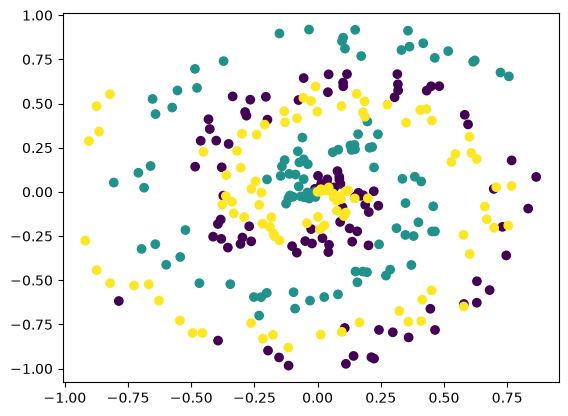

In [15]:
x, y = spiral_data(samples=100, classes=3)
plt.scatter(x[:,0], x[:,1], c=y)

plt.show()

In [16]:
print(x.shape, y.shape) # 2 inputs - 3 outputs

(300, 2) (300,)


In [17]:
# layer 1
l1 = DenseLayer(3, 2) # neurons, inputs
af1 = ActivationFunction()
op1 = af1.ReLU(l1.forward(x))

# ouput layer
l2 = DenseLayer(3, 3)
af2 = ActivationFunction()
op2 = af2.Softmax(l2.forward(op1))

op2.shape

(300, 3)

In [18]:
y_endcoded = np.eye(3)[y]
y_endcoded.shape

(300, 3)

In [19]:
loss = Loss()
ccel = loss.CatergoricalCrossEntropyLoss(y_endcoded, op2)
ccel.shape

(300,)

In [20]:
overall_loss = ccel.mean()
overall_loss

np.float64(1.1628475942350431)

In [21]:
acc = loss.accuracy(y, op2)
acc

np.float64(0.3433333333333333)

### Backpropagation

In [22]:
inputs = np.array([1, 2, 3, 4])

# Initial weights and biases
weights = np.array([
    [0.1, 0.2, 0.3, 0.4],
    [0.5, 0.6, 0.7, 0.8],
    [0.9, 1.0, 1.1, 1.2]
])

biases = np.array([0.1, 0.2, 0.3])

learning_rate = 0.001
epochs = 1000

In [23]:
z = inputs @ weights.T + biases
a = ActivationFunction().ReLU(z)
y = np.sum(a)
loss = y ** 2
loss

np.float64(466.56000000000006)

In [24]:
for i in range(epochs):
    
    z = inputs @ weights.T + biases
    a = ActivationFunction().ReLU(z)
    y = np.sum(a)

    loss = y ** 2 # single value
    dL_dy = 2 * y
    dy_da = np.ones_like(a) # 3,
    dL_da = dL_dy * dy_da # 1 * 3,1 -> 3*1
    
    da_dz = np.where(z>0, 1, 0)
    dL_dz = dL_da * da_dz

    dL_dw = np.outer(dL_dz, inputs)

    dL_db = dL_dz

    weights -= learning_rate * dL_dw
    biases -= learning_rate * dL_db

    if i % 100 == 0:
        print(loss)

466.56000000000006
0.000190172825660145
5.244645462659219e-10
1.446384677446104e-15
3.988856666940334e-21
1.101029516562194e-26
1.88760393849393e-30
6.952607099237921e-32
1.7333369499485123e-33
1.7333369499485123e-33


## NN with Forward and Backward Pass

In [46]:
# Layer Class
class Layer:
    def __init__(self, n_inputs, n_neurons):
        self.weights = 0.01 * np.random.randn(n_neurons, n_inputs)
        self.biases = np.zeros((1, n_neurons))

    def forward(self, inputs):
        self.inputs = inputs
        self.output = np.dot(self.inputs, self.weights.T) + self.biases

    def backward(self, dvalues): # predicted - actual
        self.dweights = np.dot(self.inputs.T, dvalues)
        self.dbiases = np.sum(dvalues, axis=0, keepdims=True)
        self.dinputs = np.dot(dvalues, self.weights)

# ReLU Activation
class ReLUActivation:
    def forward(self, inputs):
        self.inputs = inputs
        self.output = np.maximum(0, self.inputs)

    def backward(self, dvalues):
        self.dinputs = dvalues
        self.dinputs[self.inputs<0] = 0

In [47]:
# Softmax Activation
class Activation_Softmax:
    def forward(self, inputs):
        exp_values = np.exe(inputs-np.max(inputs, axis=1, keepdims=True))
        probabilities = exe_values / np.sum(exe_values, axis=1, keepdims=True)
        self.output = probabilities

# Loss Class
class Loss:
    def loss(self, y_true, y_pred):
        sample_losses = self.forward(y_pred, y_true)
        data_loss = np.mean(sample_losses)
        return data_loss

# CCEL
class CategoricalCrossEntropyLoss(Loss):
    
    def forward(self, y_true, y_pred):
        y_pred_clip = np.clip(y_pred, 1e-7, 1-1e-7)
        # prevent 0 and 1

        correct_confidences = np.sum(y_pred_clip * y_true, axis=1e-7)
        neg_loss_likelihood = - np.log(correct_confidences)
        return neg_loss_likelihood

    def backward(self, dvalues, y_true):
        self.dinputs = -y_true/dvalues
        self.dinputs = self.dinputs/len(dvalues[0])